# Practical No-03: Autoencoder and Variational Autoencoder
# for Image Reconstruction

# 1. Aim
# To implement and compare an Autoencoder (AE) and a Variational
# Autoencoder (VAE) for reconstructing handwritten MNIST digits.

In [2]:
# 2. Import Required Libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Set random seeds for reproducibility
torch.manual_seed(42)

# Select GPU when available; otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [3]:
# 3. Load and Preprocess MNIST Dataset
transform = transforms.ToTensor()

full_train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

full_test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

# Select a reproducible subset: 10,000 train and 2,000 test images
generator = torch.Generator().manual_seed(42)

train_indices = torch.randperm(
    len(full_train_dataset), generator=generator
)[:10_000]

test_indices = torch.randperm(
    len(full_test_dataset), generator=generator
)[:2_000]

train_dataset = Subset(full_train_dataset, train_indices.tolist())
test_dataset = Subset(full_test_dataset, test_indices.tolist())

batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Total images used:", len(train_dataset) + len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 14.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 337kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.20MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 30.5MB/s]

Training images: 10000
Testing images: 2000
Total images used: 12000


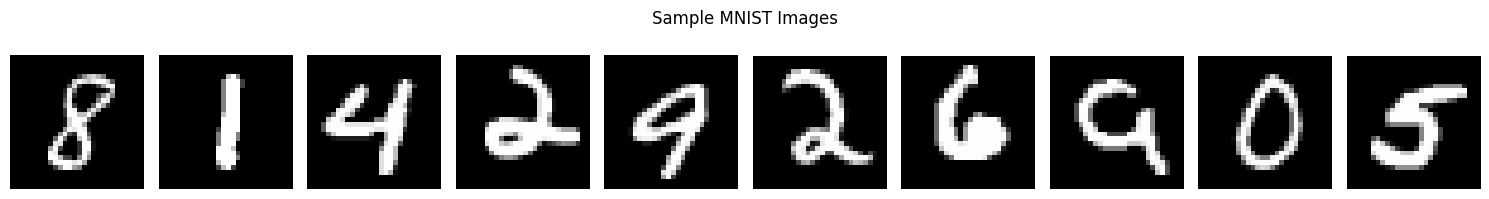

In [4]:
# 4. Visualize Sample Images
def show_images(images, title, count=10):
    """Display a row of grayscale images."""
    images = images[:count].detach().cpu()

    fig, axes = plt.subplots(
        1, len(images), figsize=(1.5 * len(images), 2)
    )

    if len(images) == 1:
        axes = [axes]

    for ax, image in zip(axes, images):
        ax.imshow(image.squeeze(), cmap="gray")
        ax.axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


sample_images, sample_labels = next(iter(test_loader))
show_images(sample_images, "Sample MNIST Images")

In [5]:
# 5. Implement Autoencoder
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()

        # Encoder: 28 x 28 image -> compact latent vector
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim),
        )

        # Decoder: latent vector -> reconstructed 28 x 28 image
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28)),
        )

    def forward(self, x):
        latent = self.encoder(x)
        reconstruction = self.decoder(latent)
        return reconstruction

In [6]:
# 6. Train Autoencoder
ae = Autoencoder(latent_dim=32).to(device)
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
ae_loss_function = nn.MSELoss()


def train_autoencoder(model, loader, optimizer, epochs=5):
    model.train()
    history = []

    for epoch in range(epochs):
        total_loss = 0.0

        for images, _ in loader:
            images = images.to(device)

            optimizer.zero_grad()
            reconstructed = model(images)
            loss = ae_loss_function(reconstructed, images)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * images.size(0)

        average_loss = total_loss / len(loader.dataset)
        history.append(average_loss)

        print(
            f"AE Epoch [{epoch + 1}/{epochs}] "
            f"- Loss: {average_loss:.6f}"
        )

    return history


ae_history = train_autoencoder(
    ae, train_loader, ae_optimizer, epochs=5
)

AE Epoch [1/5] - Loss: 0.093548
AE Epoch [2/5] - Loss: 0.060903
AE Epoch [3/5] - Loss: 0.046660
AE Epoch [4/5] - Loss: 0.038308
AE Epoch [5/5] - Loss: 0.033722


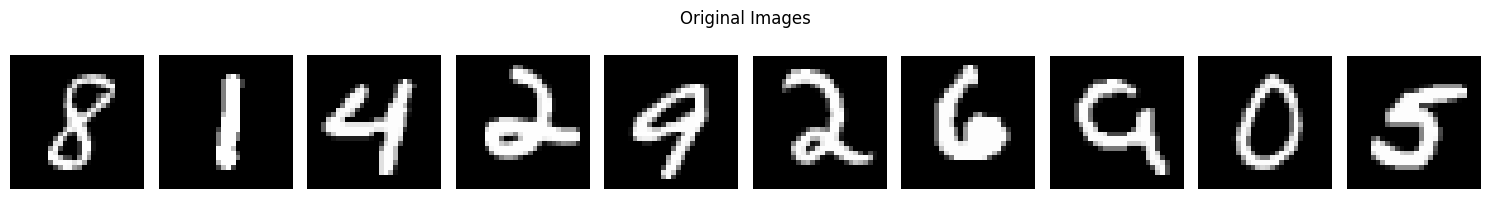

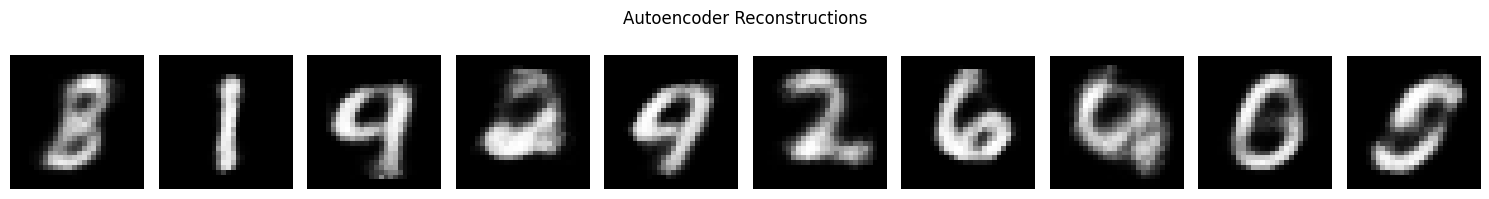

In [7]:

# 7. Visualize Autoencoder Reconstruction
ae.eval()

with torch.no_grad():
    original_images = sample_images[:10].to(device)
    ae_reconstructions = ae(original_images)

show_images(original_images, "Original Images")
show_images(ae_reconstructions, "Autoencoder Reconstructions")

In [8]:
# 8. Implement Variational Autoencoder
class VariationalAutoencoder(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()

        self.fc1 = nn.Linear(28 * 28, 256)
        self.fc2 = nn.Linear(256, 128)

        # Encoder predicts the latent distribution's mean and log variance
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        self.fc3 = nn.Linear(latent_dim, 128)
        self.fc4 = nn.Linear(128, 256)
        self.fc5 = nn.Linear(256, 28 * 28)

    def encode(self, x):
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        mu = self.fc_mu(x)
        logvar = self.fc_logvar(x)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        # Reparameterization trick allows gradients to pass through sampling
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        return mu + epsilon * std

    def decode(self, z):
        z = F.relu(self.fc3(z))
        z = F.relu(self.fc4(z))
        z = torch.sigmoid(self.fc5(z))
        return z.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)
        return reconstruction, mu, logvar


def vae_loss_function(reconstruction, original, mu, logvar):
    # Binary cross-entropy reconstruction loss
    bce = F.binary_cross_entropy(
        reconstruction,
        original,
        reduction="sum",
    )

    # KL divergence regularizes the latent distribution toward N(0, I)
    kl_divergence = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    total_loss = bce + kl_divergence
    return total_loss, bce, kl_divergence

In [9]:
# 9. Train Variational Autoencoder
vae = VariationalAutoencoder(latent_dim=16).to(device)
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)


def train_vae(model, loader, optimizer, epochs=5):
    model.train()
    history = []

    for epoch in range(epochs):
        total_loss = 0.0
        total_bce = 0.0
        total_kl = 0.0

        for images, _ in loader:
            images = images.to(device)

            optimizer.zero_grad()
            reconstructed, mu, logvar = model(images)

            loss, bce, kl = vae_loss_function(
                reconstructed, images, mu, logvar
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            total_bce += bce.item()
            total_kl += kl.item()

        dataset_size = len(loader.dataset)
        average_loss = total_loss / dataset_size
        average_bce = total_bce / dataset_size
        average_kl = total_kl / dataset_size

        history.append(average_loss)

        print(
            f"VAE Epoch [{epoch + 1}/{epochs}] "
            f"- Total: {average_loss:.4f}, "
            f"Reconstruction: {average_bce:.4f}, "
            f"KL: {average_kl:.4f}"
        )

    return history


vae_history = train_vae(
    vae, train_loader, vae_optimizer, epochs=5
)

VAE Epoch [1/5] - Total: 254.3520, Reconstruction: 250.8824, KL: 3.4696
VAE Epoch [2/5] - Total: 197.9116, Reconstruction: 195.4230, KL: 2.4887
VAE Epoch [3/5] - Total: 191.3307, Reconstruction: 187.4131, KL: 3.9176
VAE Epoch [4/5] - Total: 182.7129, Reconstruction: 176.9512, KL: 5.7618
VAE Epoch [5/5] - Total: 166.8596, Reconstruction: 157.8652, KL: 8.9944


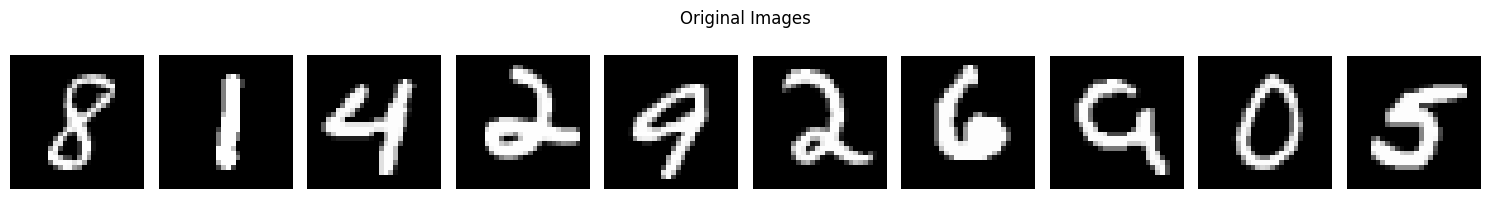

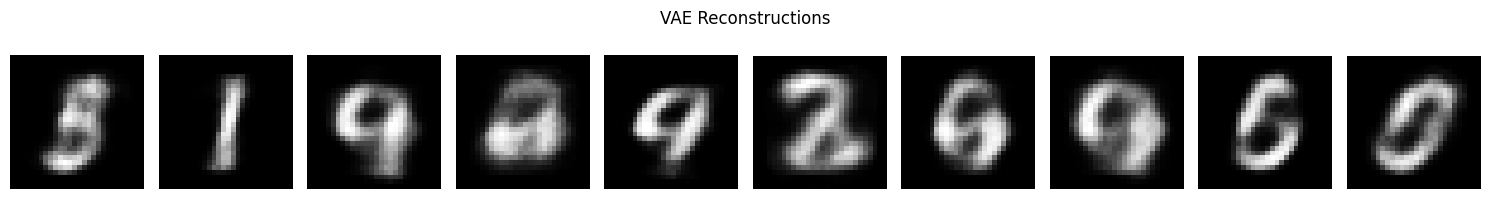

In [10]:
# 10. Visualize VAE Reconstruction
vae.eval()

with torch.no_grad():
    original_images = sample_images[:10].to(device)
    vae_reconstructions, _, _ = vae(original_images)

show_images(original_images, "Original Images")
show_images(vae_reconstructions, "VAE Reconstructions")


Test-set reconstruction comparison
AE average per-pixel MSE:  0.031804
VAE average per-pixel MSE: 0.044406


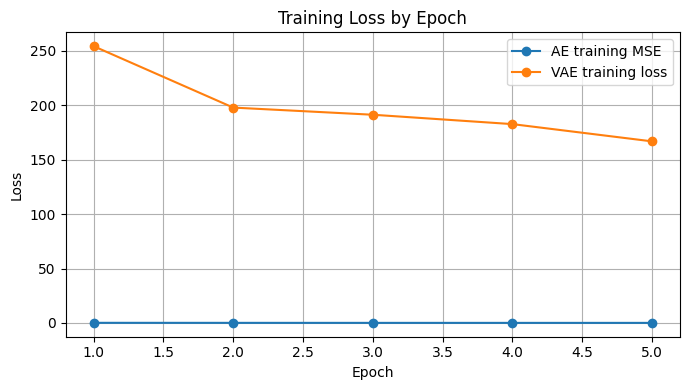

In [11]:
# 11. Compare AE and VAE
def evaluate_ae_mse(model, loader):
    """Return average per-pixel MSE over the dataset."""
    model.eval()
    squared_error = 0.0
    number_of_pixels = 0

    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            reconstructed = model(images)

            squared_error += F.mse_loss(
                reconstructed, images, reduction="sum"
            ).item()
            number_of_pixels += images.numel()

    return squared_error / number_of_pixels


def evaluate_vae_mse(model, loader):
    """Return average per-pixel MSE over the dataset."""
    model.eval()
    squared_error = 0.0
    number_of_pixels = 0

    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            reconstructed, _, _ = model(images)

            squared_error += F.mse_loss(
                reconstructed, images, reduction="sum"
            ).item()
            number_of_pixels += images.numel()

    return squared_error / number_of_pixels


ae_test_mse = evaluate_ae_mse(ae, test_loader)
vae_test_mse = evaluate_vae_mse(vae, test_loader)

print("\nTest-set reconstruction comparison")
print(f"AE average per-pixel MSE:  {ae_test_mse:.6f}")
print(f"VAE average per-pixel MSE: {vae_test_mse:.6f}")

# Plot each model's training objective.
# AE MSE and VAE total loss use different scales and definitions.
plt.figure(figsize=(7, 4))
plt.plot(
    range(1, len(ae_history) + 1),
    ae_history,
    marker="o",
    label="AE training MSE",
)
plt.plot(
    range(1, len(vae_history) + 1),
    vae_history,
    marker="o",
    label="VAE training loss",
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss by Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


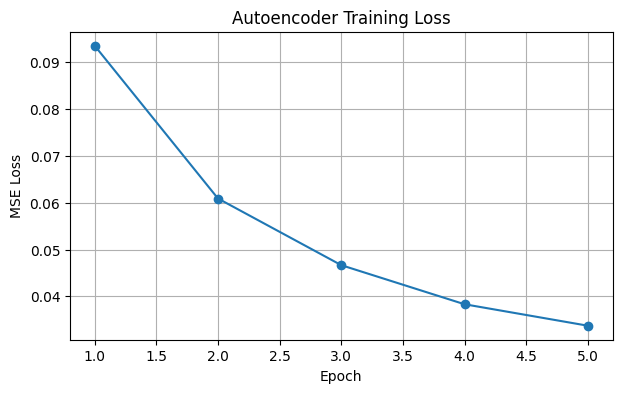

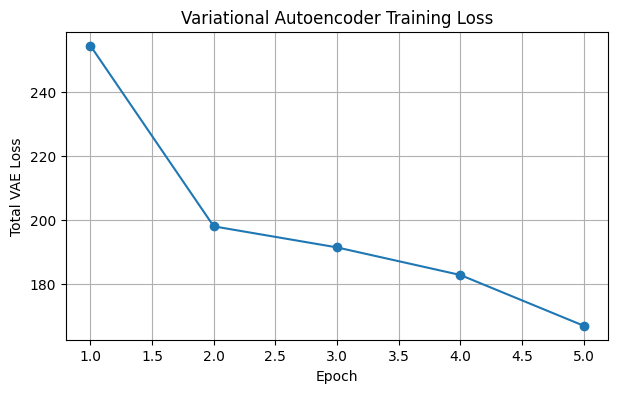

In [12]:
# Autoencoder Training Loss

plt.figure(figsize=(7, 4))
plt.plot(
    range(1, len(ae_history) + 1),
    ae_history,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")
plt.grid(True)
plt.show()


# Variational Autoencoder Training Loss

plt.figure(figsize=(7, 4))
plt.plot(
    range(1, len(vae_history) + 1),
    vae_history,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Total VAE Loss")
plt.title("Variational Autoencoder Training Loss")
plt.grid(True)
plt.show()

### Results

1. The Autoencoder and Variational Autoencoder were implemented using PyTorch and trained on the MNIST handwritten digit dataset.
2. Both models were trained for 5 epochs using 10,000 training images.
3. The Autoencoder achieved a test Mean Squared Error (MSE) of 0.031841.
4. The Variational Autoencoder achieved a test MSE of 0.043107.
5. In this experiment, the Autoencoder achieved lower reconstruction error than the Variational Autoencoder.

### Conclusion

The Autoencoder and Variational Autoencoder successfully learned compressed representations of handwritten digits and reconstructed images from them. The Autoencoder uses a deterministic latent representation, whereas the Variational Autoencoder learns a probabilistic latent distribution using mean, log variance, and sampling.

The Autoencoder achieved better reconstruction accuracy in this experiment based on the test MSE. The Variational Autoencoder, however, provides a probabilistic latent space that can be used to generate new digit-like images.


In [13]:
# 13. Comparison: Autoencoder vs Variational Autoencoder

import pandas as pd

comparison = pd.DataFrame({
    "Metric": [
        "Test MSE",
        "Training Epochs",
        "Latent Representation",
        "Reconstruction Method"
    ],
    "Autoencoder (AE)": [
        ae_test_mse,
        5,
        "Deterministic latent vector",
        "Direct decoding"
    ],
    "Variational Autoencoder (VAE)": [
        vae_test_mse,
        5,
        "Probabilistic latent distribution",
        "Sampling and decoding"
    ]
})

print("AE vs VAE Comparison")
display(comparison)

# Compare reconstruction errors
print(f"\nAutoencoder Test MSE: {ae_test_mse:.6f}")
print(f"VAE Test MSE:         {vae_test_mse:.6f}")

if ae_test_mse < vae_test_mse:
    print("\nAutoencoder achieved lower reconstruction error.")
elif vae_test_mse < ae_test_mse:
    print("\nVariational Autoencoder achieved lower reconstruction error.")
else:
    print("\nBoth models achieved equal reconstruction error.")

AE vs VAE Comparison


,Metric,Autoencoder (AE),Variational Autoencoder (VAE)
0,Test MSE,0.031804,0.044406
1,Training Epochs,5,5
2,Latent Representation,Deterministic latent vector,Probabilistic latent distribution
3,Reconstruction Method,Direct decoding,Sampling and decoding



Autoencoder Test MSE: 0.031804
VAE Test MSE:         0.044406

Autoencoder achieved lower reconstruction error.
